# Predicting NFL Quarterback Success

## Research Hypothesis
College QB decision-making, negative-play avoidance,
pocket management, and efficient rushing value predict
NFL success better than traditional passing statistics.

## Objective
Construct and evaluate NFL quarterback performance
targets, beginning with EPA per dropback.

## Initial Dataset
NFL play-by-play data from nflverse, 2023 season.

### 2.1 - Install libraries

In [2]:
import nflreadpy as nfl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)

### 2.2 - Load first dataset

In [3]:
pbp = nfl.load_pbp([2023]).to_pandas()
print("Dataset shape:", pbp.shape)
pbp.head()

Dataset shape: (49665, 372)


,play_id,game_id,old_game_id,home_team,away_team,season_type,week,posteam,posteam_type,defteam,side_of_field,yardline_100,game_date,quarter_seconds_remaining,half_seconds_remaining,game_seconds_remaining,game_half,quarter_end,drive,sp,qtr,down,goal_to_go,time,yrdln,ydstogo,ydsnet,desc,play_type,yards_gained,shotgun,no_huddle,qb_dropback,qb_kneel,qb_spike,qb_scramble,pass_length,pass_location,air_yards,yards_after_catch,run_location,run_gap,field_goal_result,kick_distance,extra_point_result,two_point_conv_result,home_timeouts_remaining,away_timeouts_remaining,timeout,timeout_team,...,drive_play_id_ended,away_score,home_score,location,result,total,spread_line,total_line,div_game,roof,surface,temp,wind,home_coach,away_coach,stadium_id,game_stadium,aborted_play,success,passer,passer_jersey_number,rusher,rusher_jersey_number,receiver,receiver_jersey_number,pass,rush,first_down,special,play,passer_id,rusher_id,receiver_id,name,jersey_number,id,fantasy_player_name,fantasy_player_id,fantasy,fantasy_id,out_of_bounds,home_opening_kickoff,qb_epa,xyac_epa,xyac_mean_yardage,xyac_median_yardage,xyac_success,xyac_fd,xpass,pass_oe
0,1.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,NaN,NaN,NaN,NaN,NaN,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,NaN,0.0,1.0,NaN,0,15:00,ARI 35,0.0,NaN,GAME,NaN,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,NaN,NaN,...,NaN,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,39.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,ARI,35.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,NaN,0,15:00,ARI 35,0.0,26.0,5-M.Prater kicks 65 yards from ARI 35 to end z...,kickoff,0.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.0,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,1.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,1.0,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,55.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,75.0,2023-09-10,900.0,1800.0,3600.0,Half1,0.0,1.0,0.0,1.0,1.0,0,15:00,WAS 25,10.0,26.0,(15:00) (Shotgun) 8-B.Robinson right tackle to...,run,3.0,1.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,right,tackle,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,0.0,NaN,NaN,B.Robinson,8.0,NaN,NaN,0.0,1.0,0.0,0.0,1.0,NaN,00-0037746,NaN,B.Robinson,8.0,00-0037746,B.Robinson,00-0037746,B.Robinson,00-0037746,0.0,1.0,-0.336103,NaN,NaN,NaN,NaN,NaN,0.515058,-51.505846
3,77.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,72.0,2023-09-10,870.0,1770.0,3570.0,Half1,0.0,1.0,0.0,1.0,2.0,0,14:30,WAS 28,7.0,26.0,(14:30) (Shotgun) 14-S.Howell pass short right...,pass,6.0,1.0,0.0,1.0,0.0,0.0,0.0,short,right,6.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,S.Howell,14.0,NaN,NaN,J.Dotson,1.0,1.0,0.0,0.0,0.0,1.0,00-0037077,NaN,00-0037741,S.Howell,14.0,00-0037077,J.Dotson,00-0037741,J.Dotson,00-0037741,0.0,1.0,0.703308,0.340652,3.328642,1.0,0.996628,0.583928,0.661106,33.889407
4,102.0,2023_01_ARI_WAS,2023091007,WAS,ARI,REG,1,WAS,home,ARI,WAS,66.0,2023-09-10,835.0,1735.0,3535.0,Half1,0.0,1.0,0.0,1.0,3.0,0,13:55,WAS 34,1.0,26.0,(13:55) 23-C.Rodriguez left guard to WAS 36 fo...,run,2.0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,left,guard,NaN,NaN,NaN,NaN,3.0,3.0,0.0,NaN,...,245.0,16,20,Home,4,36,7.0,38.0,0,outdoors,,NaN,NaN,Ron Rivera,Jonathan Gannon,WAS00,FedExField,0.0,1.0,NaN,NaN,C.Rodriguez,23.0,NaN,NaN,0.0,1.0,1.0,0.0,1.0,NaN,00-0038611,NaN,C.Rodriguez,23.0,00-0038611,C.Rodriguez,00-0038611,C.Rodriguez,00-0038611,0.0,1.0,0.469799,NaN,NaN,NaN,NaN,NaN,0.196065,-19.606467


### 2.3 - Inspect available variables

In [4]:
pbp.columns

Index(['play_id', 'game_id', 'old_game_id', 'home_team', 'away_team',
       'season_type', 'week', 'posteam', 'posteam_type', 'defteam',
       ...
       'out_of_bounds', 'home_opening_kickoff', 'qb_epa', 'xyac_epa',
       'xyac_mean_yardage', 'xyac_median_yardage', 'xyac_success', 'xyac_fd',
       'xpass', 'pass_oe'],
      dtype='str', length=372)

In [5]:
qb_columns = [
    "season",
    "week",
    "passer_player_name",
    "passer_player_id",
    "rusher_player_name",
    "rusher_player_id",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

available = [col for col in qb_columns if col in pbp.columns]

print("Available columns:")
print(available)

pbp[available].head(20)

Available columns:
['season', 'week', 'passer_player_name', 'passer_player_id', 'rusher_player_name', 'rusher_player_id', 'play_type', 'qb_dropback', 'sack', 'qb_scramble', 'air_yards', 'yards_after_catch', 'epa']


,season,week,passer_player_name,passer_player_id,rusher_player_name,rusher_player_id,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
0,2023,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,0.000000
1,2023,1,NaN,NaN,NaN,NaN,kickoff,0.0,0.0,0.0,NaN,NaN,0.000000
2,2023,1,NaN,NaN,B.Robinson,00-0037746,run,0.0,0.0,0.0,NaN,NaN,-0.336103
3,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,6.0,0.0,0.703308
4,2023,1,NaN,NaN,C.Rodriguez,00-0038611,run,0.0,0.0,0.0,NaN,NaN,0.469799
5,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,2023,1,S.Howell,00-0037077,NaN,NaN,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719


### 2.4 Filter the dataset

In [6]:
# Select only plays involving a quarterback dropback
qb_plays = pbp.loc[pbp["qb_dropback"] == 1].copy()

print("Original dataset:", pbp.shape)
print("QB dropback dataset:", qb_plays.shape)

# Inspect relevant columns
columns = [
    "passer_player_name",
    "play_type",
    "qb_dropback",
    "sack",
    "qb_scramble",
    "air_yards",
    "yards_after_catch",
    "epa"
]

qb_plays[columns].head(15)

Original dataset: (49665, 372)
QB dropback dataset: (21819, 372)


,passer_player_name,play_type,qb_dropback,sack,qb_scramble,air_yards,yards_after_catch,epa
3,S.Howell,pass,1.0,0.0,0.0,6.0,0.0,0.703308
5,S.Howell,pass,1.0,0.0,0.0,10.0,NaN,-0.521544
6,S.Howell,pass,1.0,0.0,0.0,12.0,0.0,1.173155
7,S.Howell,pass,1.0,0.0,0.0,-4.0,5.0,-0.515452
8,S.Howell,pass,1.0,0.0,0.0,3.0,NaN,-0.872005
9,S.Howell,pass,1.0,0.0,0.0,-3.0,5.0,-1.430719
13,J.Dobbs,pass,1.0,0.0,0.0,6.0,0.0,1.648779
14,J.Dobbs,pass,1.0,0.0,0.0,8.0,NaN,-0.579366
15,J.Dobbs,pass,1.0,0.0,0.0,-4.0,1.0,-1.215581
19,S.Howell,pass,1.0,0.0,0.0,4.0,2.0,0.484837


### 2.5 - Examine missing values

In [7]:
qb_plays[columns].isna().sum()

passer_player_name    1096
play_type                0
qb_dropback              0
sack                     0
qb_scramble              0
air_yards             2635
yards_after_catch     9392
epa                      0
dtype: int64

### 2.6 - Verify the dropback categories

In [8]:
print("Total QB dropbacks:", len(qb_plays))
print("Sacks:", (qb_plays["sack"] == 1).sum())
print("Scrambles:", (qb_plays["qb_scramble"] == 1).sum())
print("Neither sack nor scramble:",
    (
        (qb_plays["sack"] == 0)
        & (qb_plays["qb_scramble"] == 0)
    ).sum()
)

Total QB dropbacks: 21819
Sacks: 1459
Scrambles: 1096
Neither sack nor scramble: 19264


### 3.1 Investigate the missing passer names

In [9]:
# Examine dropbacks where passer name is missing
missing_passers = qb_plays[
    qb_plays["passer_player_name"].isna()
]

missing_passers[
    [
        "passer_player_name",
        "rusher_player_name",
        "play_type",
        "sack",
        "qb_scramble",
        "epa"
    ]
].head(15)

,passer_player_name,rusher_player_name,play_type,sack,qb_scramble,epa
50,NaN,S.Howell,run,0.0,1.0,-0.045260
134,NaN,S.Howell,run,0.0,1.0,2.813332
193,NaN,J.Allen,run,0.0,1.0,2.350573
225,NaN,J.Allen,run,0.0,1.0,0.926030
246,NaN,J.Allen,run,0.0,1.0,-0.083463
302,NaN,Z.Wilson,run,0.0,1.0,0.562715
319,NaN,J.Allen,run,0.0,1.0,0.037364
422,NaN,B.Young,run,0.0,1.0,1.168277
508,NaN,B.Young,run,0.0,1.0,-1.537297
522,NaN,D.Watson,run,0.0,1.0,2.242414


In [10]:
# Check whether all missing passer names are scrambles
missing_passers["qb_scramble"].value_counts(dropna=False)

qb_scramble
1.0    1096
Name: count, dtype: int64

### 3.2 - Construct unified QB identifier

In [11]:
# Create a unified QB name column
qb_plays["qb_name"] = qb_plays[
    "passer_player_name"
].fillna(qb_plays["rusher_player_name"])

# Create a unified QB ID column
qb_plays["qb_id"] = qb_plays[
    "passer_player_id"
].fillna(qb_plays["rusher_player_id"])

# Verify that every dropback has a QB
print("Missing QB names:", qb_plays["qb_name"].isna().sum())
print("Missing QB IDs:", qb_plays["qb_id"].isna().sum())

Missing QB names: 0
Missing QB IDs: 0


### 4 - Calculate QB EPA per dropback

In [12]:
qb_stats = (
    qb_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        dropbacks=("epa", "size"),
        total_epa=("epa", "sum"),
        sacks=("sack", "sum"),
        scrambles=("qb_scramble", "sum")
    )
)

# Calculate performance and negative-play metrics
qb_stats["epa_per_dropback"] = (
    qb_stats["total_epa"] / qb_stats["dropbacks"]
)

qb_stats["sack_rate"] = (
    qb_stats["sacks"] / qb_stats["dropbacks"]
)

qb_stats["scramble_rate"] = (
    qb_stats["scrambles"] / qb_stats["dropbacks"]
)

qb_stats.head()

,qb_id,qb_name,dropbacks,total_epa,sacks,scrambles,epa_per_dropback,sack_rate,scramble_rate
0,00-0023459,A.Rodgers,2,-2.031960,1.0,0.0,-1.015980,0.500000,0.000000
1,00-0026158,J.Flacco,265,-27.508541,12.0,2.0,-0.103806,0.045283,0.007547
2,00-0026498,M.Stafford,603,70.822678,32.0,14.0,0.117451,0.053068,0.023217
3,00-0026625,B.Hoyer,43,-8.780773,1.0,0.0,-0.204204,0.023256,0.000000
4,00-0027114,T.Morstead,1,2.670900,0.0,0.0,2.670900,0.000000,0.000000


### 5 - Rank the Quarterbacks

In [13]:
qualified_qbs = qb_stats[
    qb_stats["dropbacks"] >= 200
].copy()

qb_rankings = (
    qualified_qbs
    .sort_values("epa_per_dropback", ascending=False)
)

qb_rankings[
    [
        "qb_name",
        "dropbacks",
        "epa_per_dropback",
        "sack_rate",
        "scramble_rate"
    ]
].head(20)

,qb_name,dropbacks,epa_per_dropback,sack_rate,scramble_rate
100,B.Purdy,604,0.292405,0.052980,0.039735
29,D.Prescott,728,0.188657,0.059066,0.045330
55,J.Allen,732,0.174355,0.035519,0.077869
74,J.Love,690,0.155223,0.043478,0.036232
72,T.Tagovailoa,649,0.143452,0.047766,0.029276
40,P.Mahomes,839,0.123978,0.038141,0.075089
30,J.Goff,762,0.123121,0.048556,0.010499
59,J.Browning,284,0.119502,0.084507,0.056338
2,M.Stafford,603,0.117451,0.053068,0.023217
119,C.Stroud,613,0.113349,0.061990,0.040783


### 6.1 - Relationship between Sack Rate and EPA

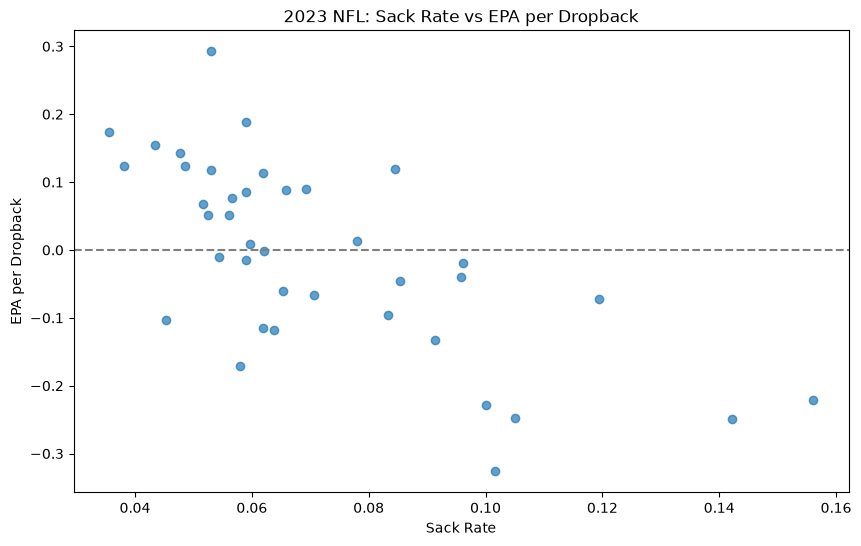

In [14]:
plt.figure(figsize=(10, 6))
plt.scatter(
    qualified_qbs["sack_rate"],
    qualified_qbs["epa_per_dropback"],
    alpha=0.7
)

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("Sack Rate")
plt.ylabel("EPA per Dropback")
plt.title("2023 NFL: Sack Rate vs EPA per Dropback")

plt.show()

### 6.2 - Calculate the correlation of sack rate and epa per dropback

In [15]:
sack_corr = qualified_qbs[
    "sack_rate"
].corr(qualified_qbs["epa_per_dropback"])

print(f"Correlation: {sack_corr:.3f}")

Correlation: -0.685


### 6.3 - Calculate the correlation of scramble rate and epa per dropback

In [16]:
scramble_corr = qualified_qbs[
    "scramble_rate"
].corr(qualified_qbs["epa_per_dropback"])

print(f"Scramble correlation: {scramble_corr:.3f}")

Scramble correlation: -0.118


### 7 - Compare the EPA of different dropback outcomes

In [17]:
qb_plays["dropback_type"] = np.select(
    [
        qb_plays["sack"] == 1, 
        qb_plays["qb_scramble"] == 1
    ],
    [
        "Sack", 
        "Scramble"
    ], default="Other dropback"
)

epa_by_type = (
    qb_plays
    .groupby("dropback_type")
    .agg(
        plays=("epa", "size"),
        mean_epa=("epa", "mean"),
        median_epa=("epa", "median")
    )
    .reset_index()
)

epa_by_type

,dropback_type,plays,mean_epa,median_epa
0,Other dropback,19264,0.116872,-0.109539
1,Sack,1459,-1.797979,-1.557734
2,Scramble,1096,0.446733,0.250660


### 8 - Interpret the Results and Test the Hypothesis

### 8.1 - What was Discovered
Sack rate: -0.685

This indicates that quarterbacks with higher sack rates generally had lower EPA/dropback during the 2023 season. That is consistent with the hypothesis about negative play avoidance. The strong negative correlation establishes a clear relationship that sacks directly contribute negatively to EPA, however this relationship is mathematical rather than evidence of an independently predictive skill. Additionally, offensive line quality, offensive scheme, and quarterback decision making can all influence sack rate.


Scramble rate: -0.118

This indicates that scrambling more frequently was not strongly associated with higher overall EPA/dropback across the qualified 2023 quarterbacks.

### 8.2 - EPA by dropback type
Scrambles produced more average EPA than other dropbacks, yet quarterbacks who scrambled more frequently did not necessarily have higher overall EPA/dropback. These results aren't contradictory. One measures the average value of individual plays; the other measures a relationship between season level quarterback statistics. For example, a quarterback could generate positive EPA when scrambling but also take too many sacks or make poor passing decisions. Also, the mean EPA of other dropbacks is positive while its median is negative. This suggests the distribution may be influenced by relatively high-value positive plays, although we'd need to inspect its shape to confirm.

### 8.3 - Important Statistical Distinction
The original hypothesis is predictive: $X_{\text{college}} \longrightarrow Y_{\text{future NFL}}$

But the current analysis is descriptive: $X_{\text{NFL 2023}} \longrightarrow Y_{\text{NFL 2023}}$

From what is done so far, its unreliable to establish that college sack avoidance predicts future NFL performance. To test that, eventually historical college QB features, subsequent NFL outcomes, and validation on quarterbacks not used to fit the model are needed.

### 9 - Isolating the Effect of Sacks
A strong negative correlation between sack rate and EPA/dropback has been found. However, because sacks directly reduce EPA, establishing how much of that correlation is simply built into the calculation is essential.

Calculating a second outcome will help: $$EPA/\text{Non-sack DB} = \frac{\sum EPA_{\text{non-sack plays}}}{N_{\text{non-sack dropbacks}}}$$

This second calculation will help us investigate whether quarterbacks who take more sacks also perform worse on plays where they aren't sacked. It won't eliminate confounding or establish causation, but it will remove the direct contribution of sacks from the comparison outcome.


### 9.1 - Calculate non-sack EPA

In [18]:
# Keep dropback that did not end in a sack
non_sack_plays = qb_plays.loc[
    qb_plays["sack"] == 0
].copy()

# Calculate QB performance on non-sack dropbacks
non_sack_stats = (
    non_sack_plays
    .groupby("qb_id", as_index=False)
    .agg(
        non_sack_dropbacks=("epa", "size"),
        non_sack_total_epa=("epa", "sum")
    )
)

non_sack_stats["non_sack_epa_per_db"] = (
    non_sack_stats["non_sack_total_epa"]
    / non_sack_stats["non_sack_dropbacks"]
)

non_sack_stats.head()

,qb_id,non_sack_dropbacks,non_sack_total_epa,non_sack_epa_per_db
0,00-0023459,1,-0.510172,-0.510172
1,00-0026158,253,-3.767114,-0.014890
2,00-0026498,571,122.052667,0.213752
3,00-0026625,42,-7.350968,-0.175023
4,00-0027114,1,2.670900,2.670900


### 9.2 - Merge with Exisiting Quarterback Statistics

In [19]:
qb_comparison = qualified_qbs.merge(
    non_sack_stats[
        ["qb_id", "non_sack_epa_per_db"]
    ],
    on="qb_id",
    how="left"
)

qb_comparison[
    [
        "qb_name",
        "sack_rate",
        "epa_per_dropback",
        "non_sack_epa_per_db"
    ]
].head()

,qb_name,sack_rate,epa_per_dropback,non_sack_epa_per_db
0,J.Flacco,0.045283,-0.103806,-0.014890
1,M.Stafford,0.053068,0.117451,0.213752
2,T.Taylor,0.077982,0.012547,0.133704
3,R.Wilson,0.085389,-0.045210,0.132390
4,K.Cousins,0.051672,0.067098,0.188269


### 9.3 Compare the Correlations

In [20]:
raw_corr = qb_comparison[
    "sack_rate"
].corr(qb_comparison["epa_per_dropback"])

adjusted_corr = qb_comparison[
    "sack_rate"
].corr(qb_comparison["non_sack_epa_per_db"])

print(f"Sack rate vs raw EPA/DB: {raw_corr:.3f}")
print(f"Sack rate vs non-sack EPA/DB: {adjusted_corr:.3f}")

Sack rate vs raw EPA/DB: -0.685
Sack rate vs non-sack EPA/DB: -0.506


The relationship weakened, but it did not disappear.

Initially we found an $r = -0.685$. Since sacks typically generate substantially negative EPA, initial expectations are that quarterbacks with higher sack rates have lower EPA/dropback. However, it's imperative to determine whether the relationship existed beyond the direct EPA penalty of sacks.

After removing sack plays from the outcome: $r = -0.506$. That is still a meaningful negative association. This suggests that quarterbacks who take sacks more frequently also tend to produce less EPA on their non-sack dropbacks. 

There could be several possible explainations, for example:
- Quarterbacks who struggle to process defenses may both take more sacks and make less effective passing decisions.
- Quarterbacks playing behind poor offensive lines may experience more sacks and worse passing conditions.
- Offensive schemes, receiver separation, and defensive competition could influence both metrics.

The important thing right now is that we cannot yet determine which explaination is responsible. A useful mathmatical observations is that we can express a quarterback's overall EPA/dropback as: $$EPA_{\text{overall}} = p_s EPA_{\text{sack}} + (1 - p_s) EPA_{\text{non-sack}}$$

where $p_s$ is the quarterback's sack rate. This is a weighted average of performance on sack and non-sack plays. That decomposition helps explain why sack rate is mechanically related to overall EPA.

### 10 - Investigate Receiver contributions to EPA
Now the next investigation is whether quarterback EPA/dropback is associated with yards gained after the catch (YAC). With this investigation were concerned with scenarios where a quarter throws a short pass and the receiver breaks several tacks to score a touchdown versus scenarios where a quarterback makes a long throw to a covered receiver for a large gain. Before any adjustments are made, exploring the relationship between YAC and EPA is useful.

## 10.1 - Isolate Completed Passes
First, completed passes must be identified, the current `qb_plays` dataset includes sacks, scrambles, incompletions, and completed passes. For this analysis, only completed passes are needed.

In [21]:
# Identify completed passes
completed_passes = qb_plays.loc[
    qb_plays["complete_pass"] == 1
].copy()

print("Completed passes:", len(completed_passes))

completed_passes[
    [
        "qb_name",
        "air_yards",
        "yards_after_catch",
        "yards_gained",
        "epa"
    ]
].head(10)

Completed passes: 12427


,qb_name,air_yards,yards_after_catch,yards_gained,epa
3,S.Howell,6.0,0.0,6.0,0.703308
6,S.Howell,12.0,0.0,12.0,1.173155
7,S.Howell,-4.0,5.0,1.0,-0.515452
9,S.Howell,-3.0,5.0,2.0,-1.430719
13,J.Dobbs,6.0,0.0,6.0,1.648779
15,J.Dobbs,-4.0,1.0,-3.0,-1.215581
19,S.Howell,4.0,2.0,6.0,0.484837
21,S.Howell,2.0,1.0,3.0,1.409476
25,S.Howell,7.0,0.0,7.0,1.590677
30,J.Dobbs,-6.0,5.0,-1.0,-0.925954


### 10.2 - Calculate how much Yardage Comes After the catch
For each completed pass: $$YAC\ Share_i = \frac{YAC_i}{YardsGained_i}$$

However, this ratio becomes difficult to interpret for zero yard and negative yard plays, and it can exceed 100% when a completion is caught behind the line of scrimmage. For the initial analysis, restricting this particular calculation to completed passes gaining positive yardage is a good idea.

In [22]:
positive_completions = completed_passes.loc[
    completed_passes["yards_gained"] > 0
].copy()

positive_completions["yac_share"] = (
    positive_completions["yards_after_catch"]
    / positive_completions["yards_gained"]
)

positive_completions[
    [
        "qb_name",
        "air_yards",
        "yards_after_catch",
        "yac_share",
        "epa"
    ]
].head(10)

,qb_name,air_yards,yards_after_catch,yac_share,epa
3,S.Howell,6.0,0.0,0.000000,0.703308
6,S.Howell,12.0,0.0,0.000000,1.173155
7,S.Howell,-4.0,5.0,5.000000,-0.515452
9,S.Howell,-3.0,5.0,2.500000,-1.430719
13,J.Dobbs,6.0,0.0,0.000000,1.648779
19,S.Howell,4.0,2.0,0.333333,0.484837
21,S.Howell,2.0,1.0,0.333333,1.409476
25,S.Howell,7.0,0.0,0.000000,1.590677
31,J.Dobbs,14.0,17.0,0.548387,2.809702
43,J.Dobbs,3.0,1.0,0.250000,-0.064859


### 10.3 - Aggregate YAC Statistics by Quarterback

In [23]:
qb_yac = (
    completed_passes
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        completions=("epa", "size"),
        total_yac=("yards_after_catch", "sum"),
        total_rec_yards=("yards_gained", "sum"),
        mean_air_yards=("air_yards", "mean"),
        completion_epa=("epa", "mean")
    )
)

qb_yac["yac_percentage"] = (
    qb_yac["total_yac"]
    / qb_yac["total_rec_yards"]
)

qb_yac.head()

,qb_id,qb_name,completions,total_yac,total_rec_yards,mean_air_yards,completion_epa,yac_percentage
0,00-0026158,J.Flacco,157,808.0,1923.0,7.101911,0.818437,0.420177
1,00-0026498,M.Stafford,351,2102.0,4332.0,6.367521,0.938728,0.485226
2,00-0026625,B.Hoyer,23,80.0,231.0,6.565217,0.906356,0.346320
3,00-0027114,T.Morstead,1,8.0,18.0,10.000000,2.670900,0.444444
4,00-0027948,B.Gabbert,18,118.0,185.0,3.722222,0.688951,0.637838


`yac_percentage` is the share of completed pass receiving yards gained after the catch, rather than the average of individual play level YAC shares.

### 10.4 - Compare YAC Dependence with Quarterback EPA
Merge YAC statisitics with the original QB performance dataset.

In [24]:
qb_yac_comparison = qualified_qbs.merge(
    qb_yac[
        ["qb_id", "completions", "yac_percentage"]
    ],
    on="qb_id",
    how="left"
)

# Correlation between YAC share and overall EPA
yac_corr = qb_yac_comparison[
    "yac_percentage"
].corr(qb_yac_comparison["epa_per_dropback"])

print(f"YAC share vs EPA/DB correlation: {yac_corr:.3f}")

YAC share vs EPA/DB correlation: -0.100


In [25]:
qb_yac_comparison[
    [
        "qb_name",
        "dropbacks",
        "completions",
        "yac_percentage",
        "epa_per_dropback"
    ]
].sort_values(
    "yac_percentage",
    ascending=False
).head(25)

,qb_name,dropbacks,completions,yac_percentage,epa_per_dropback
11,P.Mahomes,839,505,0.589224,0.123978
16,J.Browning,284,171,0.572831,0.119502
27,M.Jones,380,224,0.569811,-0.171561
3,R.Wilson,527,297,0.564495,-0.045210
17,K.Murray,305,176,0.543079,-0.014793
24,J.Burrow,402,244,0.536596,0.008593
34,T.DeVito,237,114,0.529519,-0.220437
29,S.Howell,711,388,0.511657,-0.132700
31,K.Pickett,361,201,0.501449,-0.118622
32,B.Zappe,246,127,0.500786,-0.326412


### 11 - Visualizing YAC and QB Performance
The relationship between YAC percentge and EPA/dropback: $r = -0.100$. This indicates that there's very little linear association between these variables across the qualified quarterbacks in 2023. However, correlation alone doesn't reveal the complete relationship. It's worth while to examine the actual observations, identify outliers, and determine whether other variables might explain differences between quarterbacks.

### 11.1 - Research Question
Do quarterbacks who generate a greater proportion of their passing yards through YAC tend to produce higher EPA/dropback? Visualizing the relationship between YAC percentage and EPA/dropback with a scatterplot will be useful. $X = \text{YAC Percentage}$, $Y = \text{EPA per Dropback}$. Each observation represents one qualified quarterback from the 2023 season.

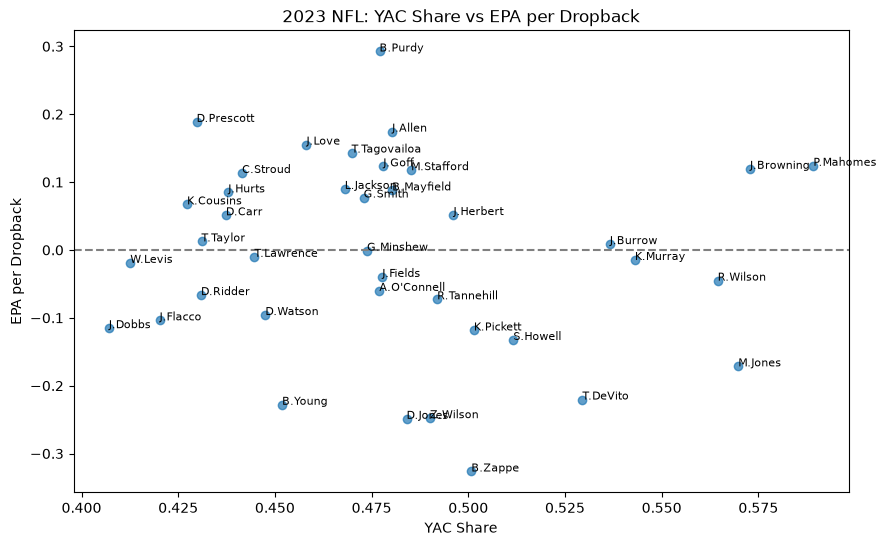

In [26]:
plt.figure(figsize=(10,6))

plt.scatter(
    qb_yac_comparison["yac_percentage"],
    qb_yac_comparison["epa_per_dropback"],
    alpha=0.7
)

for _, row in qb_yac_comparison.iterrows():
    plt.annotate(
        row["qb_name"],
        (
            row["yac_percentage"],
            row["epa_per_dropback"]
        ),
        fontsize=8
    )

plt.axhline(0, color="gray", linestyle="--")

plt.xlabel("YAC Share")
plt.ylabel("EPA per Dropback")
plt.title("2023 NFL: YAC Share vs EPA per Dropback")

plt.show()

### 11.2 - Interpret the Scatterplot
1. There is no obvious linear relationship. Quarterbacks with similar YAC percentages have substantially different EPA/dropback values. For example, around a YAC share of 0.48, we observe quarterbacks producing approximately -0.25 to +0.29 EPA/dropback. That's a substantial difference in efficiency despite relatively similar YAC dependence. 
2. There appears to be a concentration of quarterbacks around 40-50% YAC. Most observations fall in this region, with fewer quarterbacks above 55% YAC. However, that doesn't establish a meaningful statistical cluster on its own.
3. High YAC percentage doesn't guarantee high EPA. On the right side of the graph, quarterbacks with YAC shares above 55% have both positive and negative EPA/dropback values.
4. There are potential outliers worth investigating. The quarterback near 0.48 YAC share and +0.29 EPA/dropback stands out, as do several quarterbacks with EPA/dropback below -0.20.

An important statisitical distinction is that the findings do not demonstrate that YAC has no effect on quarterback performance. They demonstrate that, in this sample, YAC share alone does not explain much of the between quarterback variation in EPA/dropback through a linear relationship. There could still be nonlinear relationships, interacations with other variables, or effects obscured by offensive scheme and personel.

### 11.3 - Identify the Quarterbacks Behind the Observations

In [27]:
qb_yac_comparison[
    [
        "qb_name",
        "yac_percentage",
        "epa_per_dropback",
        "dropbacks"
    ]
].sort_values(
    "epa_per_dropback",
    ascending=False
).head(10)

,qb_name,yac_percentage,epa_per_dropback,dropbacks
30,B.Purdy,0.477048,0.292405,604
8,D.Prescott,0.429762,0.188657,728
15,J.Allen,0.480298,0.174355,732
21,J.Love,0.458162,0.155223,690
20,T.Tagovailoa,0.469832,0.143452,649
11,P.Mahomes,0.589224,0.123978,839
9,J.Goff,0.478012,0.123121,762
16,J.Browning,0.572831,0.119502,284
1,M.Stafford,0.485226,0.117451,603
38,C.Stroud,0.441519,0.113349,613


### 11.4 - Next Experiment: Air Yards Versus YAC
The next question is: Do quarterbacks with higher YAC percentages tend to throw shorter passes? This is useful because it helps to distinguish offensive styles before attempting to adjust quarterback EPA.

In [28]:
qb_air_comparison = qb_yac_comparison.merge(
    qb_yac[["qb_id", "mean_air_yards"]],
    on="qb_id",
    how="left"
)

qb_air_comparison[
    [
        "qb_name",
        "yac_percentage",
        "mean_air_yards",
        "epa_per_dropback"
    ]
].head()

,qb_name,yac_percentage,mean_air_yards,epa_per_dropback
0,J.Flacco,0.420177,7.101911,-0.103806
1,M.Stafford,0.485226,6.367521,0.117451
2,T.Taylor,0.431022,6.577586,0.012547
3,R.Wilson,0.564495,4.494949,-0.045210
4,K.Cousins,0.427284,6.180556,0.067098


In [29]:
may_corr = qb_air_comparison[
    "yac_percentage"
].corr(qb_air_comparison["mean_air_yards"])

print(f"YAC share vs mean air yards correlation: {may_corr:.3f}")

YAC share vs mean air yards correlation: -0.787


### 11.4 Interpreting Air Yards and YAC
The relationship between YAC percentge and mean air yards: $r = -0.787$. This represents a strong linear relationship in the sample. In other words, quarterbacks whose completed passes travel further through the air tend to generate a smaller proportion of their completed passing yards after the catch.

1. Why might this relationship exist? Consider two hypothetical completions: 
- Short completion: 5 air yards, 15 YAC, 20 total yards, YAC share = 75%. 
- Deep completion: 25 air yards, 5 YAC, 30 total yards, YAC share = 16.7%

Notice that deeper completion still generates positive YAC, but YAC accounts for a much smaller percentage of total yards. This reveals an important statistical issue. YAC percentage is a ratio: $$\text{YAC Share} = \frac{\text{Total YAC}}{\text{Total Receiving Yards}}$$, and approximately, for completed passes: $$\text{Receiving Yards} = \text{Air Yards} + \text{YAC}$$. As air yards increase, the denominator of YAC share can increase even if the receiver generates exactly the same number of yards after the catch. Therefore, part of the negative correlation may arise mechanically from how YAC percentage is defined. As such there should be no interpretation of the -0.787 correlation as evidence that throwing deeper necessarily reduces a receiver's ability to generate YAC.

2. Important implication for this study
These features are strongly correlated and may contain overlapping information about offensive passing style. For linear models, that could introduce multicollinearity, making individual coefficient estimates less stable and harder to interpret. It doesn't automatically mean that trashing either variable is a good idea, however understanding what each measures and whether both improve out-of-sample predictions is important. A bigger concern is that our ultimate goal is evaluating quarterback talent, not simply describing offensive style so either feature should be avoided as a direct measure of quarterback ability.

## 11.5 - Seperating YAC Volume from YAC Percentage
Just before, the relationship between YAC percentge and mean air yards was found. However, identifying what happens when YAC percentage is replaced with YAC per completion could help investigate whether the negative relationship is partly driven by the denominator.

The first step is to create the new calculation: $$\text{YAC per Completion}_i = \frac{\text{Total YAC}_i}{\text{Completions}_i}$$. From there we can go onto comparing the correlations and finally interpreting the difference.


In [30]:
qb_yac["yac_per_completion"] = (
    qb_yac["total_yac"]
    / qb_yac["completions"]
)

yac_comp_corr = qb_yac["yac_per_completion"].corr(
    qb_yac["mean_air_yards"]
)

print(f"YAC per completion versus mean air yards correlation: {yac_comp_corr:.3f}")

YAC per completion versus mean air yards correlation: 0.057


In [31]:
qb_air_comparison = qb_air_comparison.drop(
    columns=["yac_per_completion"],
    errors="ignore"
)

qb_air_comparison = qb_air_comparison.merge(
    qb_yac[["qb_id", "yac_per_completion"]],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

The results changed substantially.
- YAC percentage versus mean air yards: $r = -0.787$
- YAC per completion versus mean air yards: $r = 0.057$

The strong negative associate almost disappears. This supports the idea that the original relationship was substantially influenced by how YAC percentage is calculated. It doesn't prove that the denominator accounts for the entire relationship, but it's compelling evidence that caution it warrented for interpreting the original correlation as a football phenomenon.

### 12 - Negative Play Analysis

### 12.1 - Research Question
Do quarterbacks who generate higher EPA per dropback
avoid negative plays more frequently, experience less
severe negative outcomes, or both?

Things to investigate:
- Negative-play frequency
- Average negative-play EPA
- Median negative-play EPA
- Severe negative-play frequency

A negative play is initially defined as a dropback
with EPA < 0. This measures an unfavorable play
outcome, not necessarily a quarterback mistake.

In [32]:
negative_plays = qb_plays[
    qb_plays["epa"] < 0
].copy()

print("Total dropbacks:", len(qb_plays))
print("Negative-EPA dropbacks:", len(negative_plays))

print(
    "Negative-play percentage",
    round(len(negative_plays) / len(qb_plays) * 100, 2)
)

Total dropbacks: 21819
Negative-EPA dropbacks: 12102
Negative-play percentage 55.47


### 12.2 - Quarterback Negative-Play Frequency and Severity
Calculating the following statistics for each quarterback:

1. Negative-play count
2. Average negative-play EPA
3. Median negative-play EPA

These statistics will help distinguish how frequently negative
outcomes occur from how damaging those outcomes tend to be.

In [33]:
qb_negative_stats = (
    negative_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        negative_plays=("epa", "size"),
        mean_negative_epa=("epa", "mean"),
        median_negative_epa=("epa", "median"),
        total_negative_epa=("epa", "sum")
    )
)

qb_negative_stats.head(10)

,qb_id,qb_name,negative_plays,mean_negative_epa,median_negative_epa,total_negative_epa
0,00-0023459,A.Rodgers,2,-1.015980,-1.015980,-2.031960
1,00-0026158,J.Flacco,153,-1.287955,-0.756267,-197.057157
2,00-0026498,M.Stafford,325,-0.985880,-0.683384,-320.411130
3,00-0026625,B.Hoyer,24,-1.280166,-0.868704,-30.723982
4,00-0027948,B.Gabbert,26,-1.231603,-0.598785,-32.021680
5,00-0027973,A.Dalton,36,-0.774185,-0.584145,-27.870659
6,00-0028118,T.Taylor,123,-0.942987,-0.731526,-115.987372
7,00-0028872,J.Hekker,1,-1.941088,-1.941088,-1.941088
8,00-0028986,C.Keenum,37,-1.185912,-0.817290,-43.878746
9,00-0029263,R.Wilson,299,-1.043682,-0.697424,-312.060981


1. Understanding the results.

Stafford has more negative plays than Wilson, but Wilson's negative plays are slightly more damaging on average. Stafford also had 603 dropbacks to Wilson's 527. Comparing their negative play counts directly without accounting for their different opportunities is a mistake. Using those dropbacks as the denominators:
$$\text{Stafford Negative Rate} = \frac{325}{603} \approx 53.9\%$$
$$\text{Wilson Negative Rate} = \frac{299}{527} \approx 56.7\%$$
Stafford actually has the lower negative play rate. This demonstrates why rates are generally more useful than raw counts when comparing players with different workloads.

2. The mathmatical relationship.

A quarterback's EPA per dropback can be decomposed into two componenets: $$\boxed{\overline{EPA} = p_- \mu_- + (1 - p_-) \mu_{\geq 0}}$$
Where:
- $p_-$: proportion of negative EPA dropbacks.
- $\mu_-$: average EPA on negative plays.
- $\mu_{\geq 0}$: average EPA on nonnegative plays.


### 12.3 - Normalize Negative Plays by Dropbacks

Raw negative-play counts are influenced by playing time. To compare quarterbacks fairly, calculating the proportion of their total dropbacks that produce negative EPA will help. Negative-play rate = Negative plays / Total dropbacks

In [34]:
qb_negative_comparison = qualified_qbs.merge(
    qb_negative_stats[
        [
            "qb_id",
            "negative_plays",
            "mean_negative_epa",
            "median_negative_epa",
            "total_negative_epa"
        ]
    ],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

qb_negative_comparison["negative_play_rate"] = (
    qb_negative_comparison["negative_plays"]
    / qb_negative_comparison["dropbacks"]
)

qb_negative_comparison[
    [
        "qb_name",
        "dropbacks",
        "negative_play_rate",
        "mean_negative_epa",
        "median_negative_epa",
        "epa_per_dropback"
    ]
].sort_values(
    "negative_play_rate",
    ascending=True
).head(15)

,qb_name,dropbacks,negative_play_rate,mean_negative_epa,median_negative_epa,epa_per_dropback
30,B.Purdy,604,0.471854,-1.017559,-0.759479,0.292405
8,D.Prescott,728,0.490385,-1.015633,-0.709815,0.188657
15,J.Allen,732,0.493169,-0.947567,-0.695176,0.174355
9,J.Goff,762,0.503937,-1.052583,-0.697617,0.123121
11,P.Mahomes,839,0.512515,-0.966601,-0.630934,0.123978
13,L.Jackson,636,0.512579,-1.011690,-0.700510,0.089907
20,T.Tagovailoa,649,0.516179,-1.057898,-0.693509,0.143452
6,G.Smith,548,0.516423,-0.980642,-0.742400,0.077232
16,J.Browning,284,0.521127,-1.014977,-0.692383,0.119502
24,J.Burrow,402,0.527363,-0.990826,-0.666127,0.008593


### 12.4 - Decomposing EPA into positive and negative outcomes

Research Question: Do quarterbacks with higher EPA per dropback generate positive outcomes more frequently, produce more valuable positive outcomes, or both? A positive play is defined as a dropback with EPA > 0. Calculating positive-play counts, mean positive EPA, median positive EPA, and total positive EPA.

Measuring positive play production and test whether it helps explain differences between quarterbacks. That's defined: $$p_+ = \frac{\text{Positive-EPA dropbacks}}{\text{Total dropbacks}}$$ $$\mu_+ = \text{Mean EPA on positive-EPA dropbacks}$$
Now to express overall EPA per dropback as: $$\overline{EPA} = p_+ \mu_+ + p_- \mu_-$$
Zero EPA plays contribute nothing to the numerator but remain in the total dropback denominator.



In [35]:
positive_plays = qb_plays[
    qb_plays["epa"] > 0
].copy()

print("Total dropbacks:", len(qb_plays))
print("Positive EPA dropbacks:", len(positive_plays))

print(
    "Positive play percentage:",
    round(len(positive_plays) / len(qb_plays) * 100, 2)
)

Total dropbacks: 21819
Positive EPA dropbacks: 9717
Positive play percentage: 44.53


In [36]:
qb_positive_stats = (
    positive_plays
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        positive_plays=("epa", "size"),
        mean_positive_epa=("epa", "mean"),
        median_positive_epa=("epa", "median"),
        total_positive_epa=("epa", "sum")
    )
)

qb_positive_stats.head(15)

,qb_id,qb_name,positive_plays,mean_positive_epa,median_positive_epa,total_positive_epa
0,00-0026158,J.Flacco,112,1.513827,1.197115,169.548616
1,00-0026498,M.Stafford,278,1.407316,1.202674,391.233808
2,00-0026625,B.Hoyer,19,1.154906,1.174569,21.943209
3,00-0027114,T.Morstead,1,2.670900,2.670900,2.670900
4,00-0027948,B.Gabbert,14,1.390876,1.223083,19.472265
5,00-0027973,A.Dalton,26,1.294385,1.000413,33.653997
6,00-0028118,T.Taylor,95,1.249712,0.818936,118.722627
7,00-0028986,C.Keenum,22,1.055792,0.727613,23.227417
8,00-0029263,R.Wilson,228,1.264190,0.909910,288.235386
9,00-0029604,K.Cousins,150,1.446433,1.215243,216.964886


### 12.5 - Combine Positive and Negative Outcomes
Research Question: How much of each quarterback's EPA per dropback comes from generating positive outcomes versus absorbing negative outcomes?

In [43]:
qb_positive_comparison = qb_negative_comparison.merge(
    qb_positive_stats[
        [
            "qb_id",
            "positive_plays",
            "mean_positive_epa",
            "median_positive_epa",
            "total_positive_epa"
        ]
    ],
    on="qb_id",
    how="left",
    validate="one_to_one"
)

qb_positive_comparison["positive_play_rate"] = (
    qb_positive_comparison["positive_plays"]
    / qb_positive_comparison["dropbacks"]
)

qb_positive_comparison["reconstructed_epa_per_db"] = (
    (
        qb_positive_comparison["positive_play_rate"]
        * qb_positive_comparison["mean_positive_epa"]
    ) 
    +
    (
        qb_positive_comparison["negative_play_rate"]
        * qb_positive_comparison["mean_negative_epa"]
    )
)

qb_positive_comparison["reconstruction_error"] = (
    qb_positive_comparison["reconstructed_epa_per_db"]
    - qb_positive_comparison["epa_per_dropback"]
)

print(
    "Maximum absolute reconstruction error:",
    qb_positive_comparison["reconstruction_error"].abs().max()
)

qb_positive_comparison[
    [
        "qb_name",
        "dropbacks",
        "negative_play_rate",
        "mean_negative_epa",
        "median_negative_epa",
        "positive_play_rate",
        "mean_positive_epa",
        "median_positive_epa",
        "reconstructed_epa_per_db",
        "epa_per_dropback"
    ]
].sort_values(
    "reconstructed_epa_per_db",
    ascending=False
).head(15)

Maximum absolute reconstruction error: 1.6653345369377348e-16


,qb_name,dropbacks,negative_play_rate,mean_negative_epa,median_negative_epa,positive_play_rate,mean_positive_epa,median_positive_epa,reconstructed_epa_per_db,epa_per_dropback
30,B.Purdy,604,0.471854,-1.017559,-0.759479,0.528146,1.462749,1.207524,0.292405,0.292405
8,D.Prescott,728,0.490385,-1.015633,-0.709815,0.509615,1.347502,1.058114,0.188657,0.188657
15,J.Allen,732,0.493169,-0.947567,-0.695176,0.506831,1.266037,0.993921,0.174355,0.174355
21,J.Love,690,0.533333,-0.932892,-0.643109,0.466667,1.398784,1.110125,0.155223,0.155223
20,T.Tagovailoa,649,0.516179,-1.057898,-0.693509,0.483821,1.425147,1.213350,0.143452,0.143452
11,P.Mahomes,839,0.512515,-0.966601,-0.630934,0.487485,1.270553,1.058976,0.123978,0.123978
9,J.Goff,762,0.503937,-1.052583,-0.697617,0.496063,1.317488,1.127596,0.123121,0.123121
16,J.Browning,284,0.521127,-1.014977,-0.692383,0.478873,1.354082,1.084545,0.119502,0.119502
1,M.Stafford,603,0.538972,-0.985880,-0.683384,0.461028,1.407316,1.202674,0.117451,0.117451
38,C.Stroud,613,0.538336,-1.000788,-0.751908,0.461664,1.412520,1.218547,0.113349,0.113349


Maximum reconstruction error: $1.67 \times 10^{-16}$
The reconstructed EPA/dropback matches the original values to floating point precision. This confirms the relationship: $$\overline{EPA} = p_+\mu_+ + p_-\mu_-$$
where $p_+$ and $p_-$ are the proportions of positive and negative plays, and $\mu_+$ and $\mu_-$ are their respective average EPA values.

Example:
- Brock Purdy, Positive play rate: 52.81%, Mean positive EPA: +1.463, Overall EPA/DB: +0.292
- Jordan Love, Positive play rate: 46.67%, Mean positive EPA: +1.398, Overall EPA/DB: +0.155
- Patrick Mahomes, Positive play rate: 48.75%, Mean positive EPA: +1.271, Overall EPA/DB: 0.124

Notice that Jordan Love had a lower positive play rate than Mahomes, yet a higher overall EPA/dropback. That demonstrates why it's irresponsible to judge quarterback effectiveness using positive play frequency alone. One critical distinction: this reconstruction is a mathmatical identity, not a predictive model. It's possible to explain how the observed EPA average is composed, but it's not a reliable explaination for why quarterbacks produce these outcomes.


### 12.6 - Measuring game to game consistency
Calculating EPA per dropback for each quarterback in each game during the 2023 NFL season.

Research question:
Do quarterbacks with higher average EPA/dropback also exhibit lower game-to-game variability?

In [46]:
qb_game_stats = (
    qb_plays
    .groupby(["qb_id", "qb_name", "game_id"], as_index=False)
    .agg(
        game_dropbacks=("epa", "size"),
        game_total_epa=("epa", "sum"),
        game_mean_epa=("epa", "mean")
    )
)

qb_game_stats.head(10)

,qb_id,qb_name,game_id,game_dropbacks,game_total_epa,game_mean_epa
0,00-0023459,A.Rodgers,2023_01_BUF_NYJ,2,-2.031960,-1.015980
1,00-0026158,J.Flacco,2023_13_CLE_LA,46,-7.791564,-0.169382
2,00-0026158,J.Flacco,2023_14_JAX_CLE,46,-7.339273,-0.159549
3,00-0026158,J.Flacco,2023_15_CHI_CLE,48,-17.392163,-0.362337
4,00-0026158,J.Flacco,2023_16_CLE_HOU,43,20.085988,0.467116
5,00-0026158,J.Flacco,2023_17_NYJ_CLE,30,1.736629,0.057888
6,00-0026158,J.Flacco,2023_19_CLE_HOU,52,-16.808159,-0.323234
7,00-0026498,M.Stafford,2023_01_LA_SEA,39,21.533918,0.552152
8,00-0026498,M.Stafford,2023_02_SF_LA,59,-5.869871,-0.099489
9,00-0026498,M.Stafford,2023_03_LA_CIN,40,-5.875214,-0.146880


### 12.7 - Filtering low volume games
Game-level EPA estimates based on very few dropbacks may be unstable.

Before calculating quarterback consistency, an examination of the distribution of dropbacks per game and an evaluation of the impact of excluding low-volume games is useful.

In [47]:
qb_game_stats["game_dropbacks"].describe()

count    723.000000
mean      30.178423
std       15.391924
min        1.000000
25%       24.000000
50%       34.000000
75%       41.000000
max       70.000000
Name: game_dropbacks, dtype: float64

In [ ]:
minimum_dropbacks = 20

low_volume_games = qb_game_stats[
    qb_game_stats["game_dropbacks"] < minimum_dropbacks
]

print("Total QB-game observations:", len(qb_game_stats))
print("Low-volume observations:", len(low_volume_games))

Total QB-game observations: 723
Low-volume observations: 156


A few observations:
- Median = 34: Half of the QB game observations contain 34 of fewer dropbacks, and half contain 34 or more.
- Minimum = 1: Some game averages are calculated from a single dropback, making them particularly unstable.
- 156 low volume observations: Excluding them removes approximately one-fifth of the QB game observations.

That last result matters. Removing a substantial portion of the observations can cause a big effect so a sensitivity analysis using alternative thresholds, such as 10, 20, and 30 dropbacks should be performed. Also those 156 observations may not be randomly distributed. Backup quarterbacks, injured starters, and quarterbacks who were benched could be disproportionately affected. This creates a potential selection bias: the filtered sample may represent quarterbacks who remained on the field rather than all quarterbacks who participated. For now, proceeding with 20 dropback is preferable for the exploratory threshold.

### 12.8 - Measuring Game-to-Game Consistency

Excluding quarterback-game observations with fewer than 20 dropbacks before calculating game-level EPA variability. This threshold is provisional and will be evaluated through sensitivity analysis.
The sample standard deviation is: $$s_i = \sqrt{\frac{1}{n_i - 1} \sum_{j=1}^{n_i} (EPA_{ij} - \overline{EPA_i})^2}$$
Where:
- $n_i$ = number of qualifying games for quarterback $i$
- $EPA_{ij}$ = quarterback $i$'s EPA/dropback in game $j$
- $\overline{EPA_i}$ = average of his qualifying game-level EPA/dropback values
- $s_i$ = standard deviation of those game-level values
A smaller $s_i$ means his game-level EPA/dropback is more tightly concentrated around his average. It does not necessarily mean he is a better quarterback.

In [49]:
qualified_games = qb_game_stats[
    qb_game_stats["game_dropbacks"] >= minimum_dropbacks
].copy()

print("Qualified QB game observations:", len(qualified_games))

qualified_games.head()

Qualified QB game observations: 567


,qb_id,qb_name,game_id,game_dropbacks,game_total_epa,game_mean_epa
1,00-0026158,J.Flacco,2023_13_CLE_LA,46,-7.791564,-0.169382
2,00-0026158,J.Flacco,2023_14_JAX_CLE,46,-7.339273,-0.159549
3,00-0026158,J.Flacco,2023_15_CHI_CLE,48,-17.392163,-0.362337
4,00-0026158,J.Flacco,2023_16_CLE_HOU,43,20.085988,0.467116
5,00-0026158,J.Flacco,2023_17_NYJ_CLE,30,1.736629,0.057888


In [50]:
qb_consistency = (
    qualified_games
    .groupby(["qb_id", "qb_name"], as_index=False)
    .agg(
        games=("game_id", "size"),
        mean_game_epa=("game_mean_epa", "mean"),
        std_game_epa=("game_mean_epa", "std")
    )
)

qb_consistency.head(10)

,qb_id,qb_name,games,mean_game_epa,std_game_epa
0,00-0026158,J.Flacco,6,-0.081583,0.307092
1,00-0026498,M.Stafford,16,0.116620,0.248499
2,00-0026625,B.Hoyer,1,-0.410092,NaN
3,00-0027948,B.Gabbert,1,-0.166953,NaN
4,00-0027973,A.Dalton,1,0.093280,NaN
5,00-0028118,T.Taylor,4,0.066159,0.127877
6,00-0028986,C.Keenum,2,-0.485420,0.594598
7,00-0029263,R.Wilson,15,-0.046003,0.259815
8,00-0029604,K.Cousins,8,0.040175,0.334347
9,00-0029701,R.Tannehill,8,-0.030948,0.267602


### 12.8 - Review Results
567 qualifying QB game observations remain.
Something to consider: Tyrod Taylor has a lower standard deviation, suggesting more consistent game level EPA across the games included. However, he only has four qualifying games compared with Stafford's sixteen. Four observations provide a much less reliable estimate of a quarterback's underlying game-to-game variability than sixteen observations. This introduces another problem: the number of games used to estimate consistency matters. Also, the NaN values for quarterbacks with one qualifying game are expected. Pandas uses the sample standard deviation, which requires at least two observations.

### 12.9 - Establish a minimum number of games
To reduce instability in game-to-game consistency estimates, eight qualifying games is required. This ensures that the standard deviation estimates are based on multiple observations, although the estimates may still contain substantial sampling uncertainty. That leaves the analysis with two conditions: $$\text{Qualifies} = \begin{cases} 1 & \text{if at least 8 games have 20+ dropbacks each} \\ 0 & \text{otherwise} \end{cases}$$
Eight games is a provisional research decision, not a statistical guarantee of reliability, later an evaluation of alternative thresholds and how they affect the results is recommended.

In [51]:
minimum_games = 8

qualified_consistency = qb_consistency[
    qb_consistency["games"] >= minimum_games
].copy()

print("Quarterbacks remaining:", len(qualified_consistency))

qualified_consistency.head(10)

Quarterbacks remaining: 33


,qb_id,qb_name,games,mean_game_epa,std_game_epa
1,00-0026498,M.Stafford,16,0.116620,0.248499
7,00-0029263,R.Wilson,15,-0.046003,0.259815
8,00-0029604,K.Cousins,8,0.040175,0.334347
9,00-0029701,R.Tannehill,8,-0.030948,0.267602
10,00-0030565,G.Smith,15,0.057332,0.269065
11,00-0031280,D.Carr,17,0.074823,0.254847
19,00-0033077,D.Prescott,18,0.193449,0.269532
20,00-0033106,J.Goff,20,0.141484,0.213188
25,00-0033873,P.Mahomes,20,0.139427,0.242720
27,00-0033949,J.Dobbs,13,-0.116776,0.313222


In [52]:
qualified_consistency[
    ["qb_name", "games", "mean_game_epa", "std_game_epa"]
].sort_values(
    "std_game_epa",
    ascending=True
).head(15)

,qb_name,games,mean_game_epa,std_game_epa
39,G.Minshew,14,0.031104,0.180754
64,W.Levis,8,0.029918,0.189468
52,Z.Wilson,11,-0.227383,0.212348
20,J.Goff,20,0.141484,0.213188
35,J.Browning,8,0.118292,0.226793
32,J.Allen,18,0.185248,0.236023
46,J.Hurts,17,0.113713,0.236058
25,P.Mahomes,20,0.139427,0.242720
1,M.Stafford,16,0.116620,0.248499
57,D.Ridder,12,-0.023250,0.249793


### 12.10 - Interpret the Consistency Rankings
1. Consistency and performance are different dimensions. Zach Wilson has a relatively low standard deviation, but his mean games EPA/dropback is substantially negative. Josh Allen has a somewhat higher standard deviation and much stronger average performance.
2. Consistency doesn't establish talent. Jared Goff's performance might reflect some combination of quarterback ability, offensive scheme, pass protection, receiver performance, and opponent strength. It's impossible to isolate those contributions from these statistics.
3. Consistency may not be stable across seasons. A quarterback could be consistent in 2023 and highly variable in 2024. If so, consistency might reflect temporary circumstances rather than a persistent quarterback characteristic. This is something to test eventually.

### 12.11 - Visualize performance versus consistency
The two variables that describe different aspects of quarterback performance:
- `mean_game_epa`: average performance across qualifying games.
- `std_game_epa`: variation in performance across those games.
Rather than ranking quarterbacks on one metric, both of these variables can be visualized simultaneously.

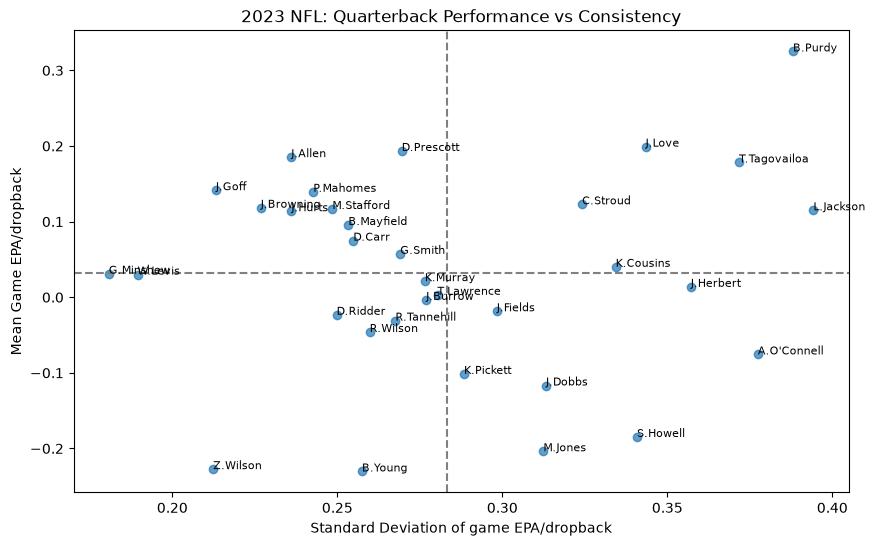

In [60]:
plt.figure(figsize=(10,6))

plt.scatter(
    qualified_consistency["std_game_epa"],
    qualified_consistency["mean_game_epa"],
    alpha=0.7
)

for _, row in qualified_consistency.iterrows():
    plt.annotate(
        row["qb_name"],
        (
            row["std_game_epa"],
            row["mean_game_epa"]
        ),
        fontsize=8
    )

plt.axhline(qualified_consistency["mean_game_epa"].mean(), color="gray", linestyle="--")
plt.axvline(qualified_consistency["std_game_epa"].mean(), color="gray", linestyle="--")

plt.xlabel("Standard Deviation of game EPA/dropback")
plt.ylabel("Mean Game EPA/dropback")
plt.title("2023 NFL: Quarterback Performance vs Consistency")

plt.show()